In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler



In [69]:
X, y = make_blobs(n_samples=300, centers=3, n_features=2,
                  random_state=42)

In [70]:
data = pd.DataFrame(X,columns=['feature_1','Feature_2'])

In [71]:
data

,feature_1,Feature_2
0,-7.338988,-7.729954
1,-7.740041,-7.264665
2,-1.686653,7.793442
3,4.422198,3.071947
4,-8.917752,-7.888196
...,...,...
295,-3.660191,9.389984
296,3.810884,1.412989
297,-4.116681,9.198920
298,-6.861209,-5.203672


In [72]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [73]:
inertia = []
K_range = range(1,11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

In [74]:
inertia

[599.9999999999999,
 187.79991946175906,
 18.26315933089595,
 15.560044601263483,
 12.751104241656348,
 11.74033756354786,
 10.970647800369436,
 8.804033742898566,
 8.104680274681062,
 7.020157763144604]

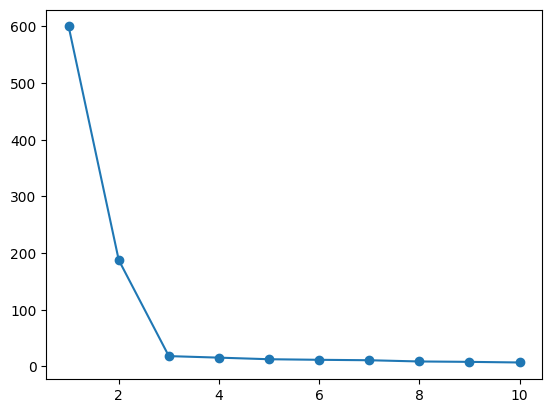

In [75]:
plt.plot(K_range,inertia,marker='o')

In [76]:
k_means_final = KMeans(n_clusters=3, random_state=42)


In [77]:
cluster_labels = k_means_final.fit_predict(X_scaled)

In [78]:
data['cluster'] = cluster_labels

<Axes: xlabel='Feature_2', ylabel='feature_1'>

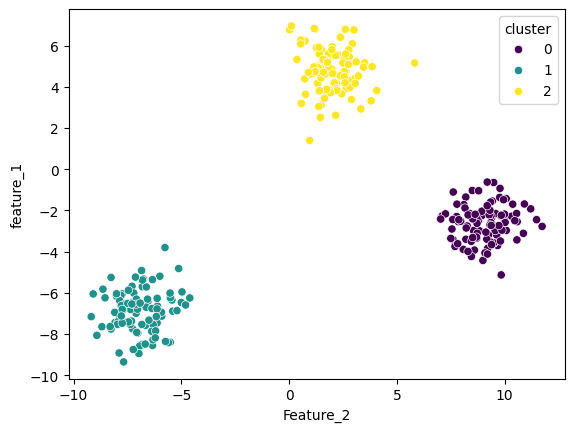

In [79]:
sns.scatterplot(
    x=data['Feature_2'],
    y=data['feature_1'],
    hue=data['cluster'],
    palette='viridis'
)